# Project Part 1 - Flow Matching on a Torus
Group 5

In [3]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

Generate the **Torus**
(generate uniform torus dataset)
theta is uniform, phy is sampled by rejection

In [4]:
def sample_uniform_torus(N, R, r):
    phi_samples = []

    # Rejection sampling for phi
    while len(phi_samples) < N:
        # Candidate phi
        phi_candidate = np.random.uniform(0, 2 * np.pi)

        # Acceptance probability
        acceptance_probability = (3 + np.cos(phi_candidate)) / 4

        # Accept or reject
        if np.random.rand() < acceptance_probability:
            phi_samples.append(phi_candidate)

    phi = np.array(phi_samples)
    # theta is uniformly distributed
    theta = np.random.uniform(0,2 * np.pi,N)

    # Torus parameterization
    x = (R + r * np.cos(phi)) * np.cos(theta)
    y = (R + r * np.cos(phi)) * np.sin(theta)
    z = r * np.sin(phi)

    return np.column_stack([x, y, z])

# Data to PyTorch

In [5]:
R = 3.0
r = 1.0
N = 20_000

torus = sample_uniform_torus(N, R, r)
torus_data = torch.tensor(torus,dtype=torch.float32)
print(torus_data.shape)

torch.Size([20000, 3])


**Visualize** the Torus dataset

Checking 20000 points -> target distribution. Uniform surface area, not uniform phi.

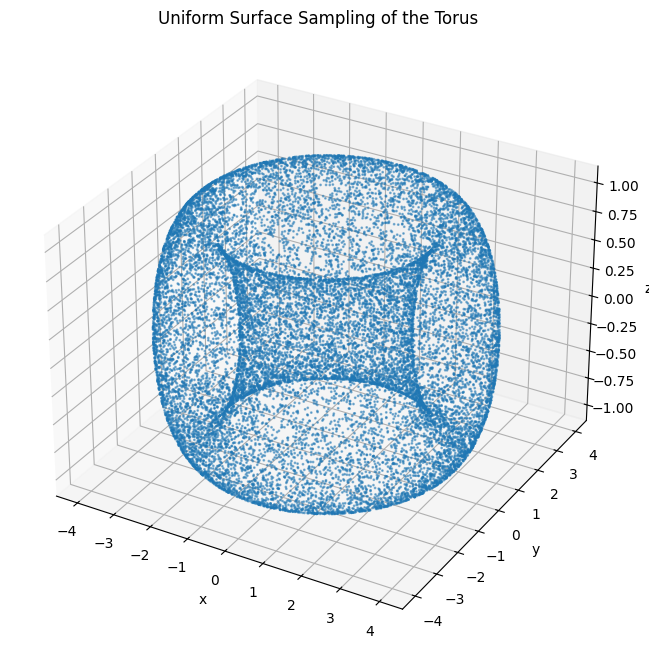

In [6]:
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    torus_data[:, 0],
    torus_data[:, 1],
    torus_data[:, 2],
    s=1,
    alpha=0.5)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

ax.set_title("Uniform Surface Sampling of the Torus")

plt.show()

# Create the flow matching training pairs.

Train a neural network to learn v(theta)(x,t). Velocity of the cloud distribution.

The model will receive (x,y,z,t) and predict (vx,vy,vz)

- x0: Gaussian noise
- x1: a point from our torus
- t: random time between 0 and 1
- xt: point between xo and x1
- ut: target velocity

xt = (1-t)x0 + tx1
ut = x1 - x0

network will learn v0(xt,t)=ut

In [7]:
def create_flow_matching_batch(data, batch_size=512):
    # Randomly select points from target distribution
    indices = torch.randint(0,len(data),(batch_size,))
    x1 = data[indices]

    # Source distribution: Gaussian noise
    x0 = torch.randn_like(x1)

    # Random time between [0,1]
    t = torch.rand(batch_size, 1)

    # Point along the straight path. Interpolation
    xt = (1 - t) * x0 + t * x1

    # Target velocity
    target_velocity = x1 - x0

    return x0, x1, xt, t, target_velocity

In [8]:
#Testing
x0, x1, xt, t, target_velocity = create_flow_matching_batch(
    torus_data,
    batch_size=512)

print("x0:", x0.shape)
print("x1:", x1.shape)
print("xt:", xt.shape)
print("t:", t.shape)
print("target velocity:", target_velocity.shape)

x0: torch.Size([512, 3])
x1: torch.Size([512, 3])
xt: torch.Size([512, 3])
t: torch.Size([512, 1])
target velocity: torch.Size([512, 3])


# Build the neural network using a small MLP (multilayer perceptron)

A model that learns the velocity field

4 dimensions -> 3 dimensions
4 hidden layers
256 neurons per hidden layer
SiLU activation

In [9]:
class FlowModel(nn.Module):

  def __init__(self):
      super().__init__()
      self.network = nn.Sequential(
          nn.Linear(4, 256),
          nn.SiLU(),

          nn.Linear(256, 256),
          nn.SiLU(),

          nn.Linear(256, 256),
          nn.SiLU(),

          nn.Linear(256, 256),
          nn.SiLU(),

          nn.Linear(256, 3)
      )

  def forward(self, x, t):
      # x = [x, y, z]
      # t = [time]
      xt = torch.cat([x, t], dim=1) #[x,y,z,t]

      return self.network(xt)

Create the model
Output: sequence of linear + SiLU layers

In [10]:
model = FlowModel()
print(model)

#optimizer = optim.Adam(model.parameters(),lr=1e-3)

FlowModel(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=256, bias=True)
    (1): SiLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): SiLU()
    (4): Linear(in_features=256, out_features=256, bias=True)
    (5): SiLU()
    (6): Linear(in_features=256, out_features=256, bias=True)
    (7): SiLU()
    (8): Linear(in_features=256, out_features=3, bias=True)
  )
)


In [11]:
test_output = model(xt, t)

print(test_output.shape)

torch.Size([512, 3])


# Train the Flow Matching Model

batch size = 512
iterations = 5000
Adam
Learning rate = 10^-3,
gradient clipping = 1

In [12]:
optimizer = optim.Adam(model.parameters(),lr=1e-3)

In [13]:
batch_size = 512
num_steps = 5000
loss_history = []

for step in range(num_steps):

    # Create a new Flow Matching batch
    x0, x1, xt, t, target_velocity = create_flow_matching_batch(
        torus_data,
        batch_size
    )

    # Neural network prediction
    predicted_velocity = model(xt,t)

    # Flow Matching objective
    loss = ((predicted_velocity - target_velocity) ** 2).mean()

    # Backpropagation
    optimizer.zero_grad()
    loss.backward()

    # Gradient clipping
    torch.nn.utils.clip_grad_norm_(model.parameters(),max_norm=1.0)
    optimizer.step()
    loss_history.append(loss.item())

    if (step + 1) % 500 == 0:
        print(
            f"Iteration {step + 1}/{num_steps}, | "
            f"Loss: {loss.item():.6f}")

Iteration 500/5000, | Loss: 2.906260
Iteration 1000/5000, | Loss: 2.599886
Iteration 1500/5000, | Loss: 2.402238
Iteration 2000/5000, | Loss: 2.450006
Iteration 2500/5000, | Loss: 2.667836
Iteration 3000/5000, | Loss: 2.575206
Iteration 3500/5000, | Loss: 2.425863
Iteration 4000/5000, | Loss: 2.569471
Iteration 4500/5000, | Loss: 2.570760
Iteration 5000/5000, | Loss: 2.470849


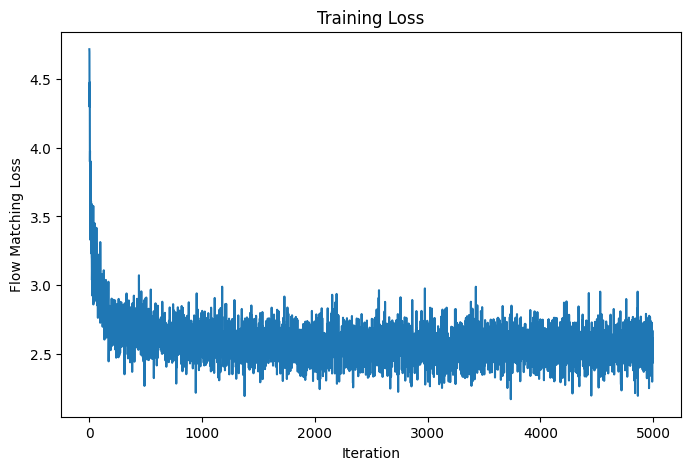

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.xlabel("Iteration")
plt.ylabel("Flow Matching Loss")
plt.title("Training Loss")

plt.show()

In [15]:
torch.save(model.state_dict(),"flow_matching_torus.pt")

Generate from the model. Using simple Euler integration



In [16]:
def generate_samples(model, n_samples=2000, num_steps=100):
    # Start from Gaussian noise
    x = torch.randn(n_samples, 3)
    #Euler step size
    dt = 1.0 / num_steps

    with torch.no_grad():
        for k in range(num_steps):
            # Current time
            t = torch.full((n_samples, 1), k/num_steps)

            # Learned velocity
            velocity = model(x, t)

            # Euler step
            x = x + dt * velocity
    return x

# Method A: Unscontrained Flow Matching

In [17]:
#METHOD A: Unconstrained Flow Matching. Baseline.
generated_A = generate_samples(model, n_samples=2000, num_steps=100)

print(generated_A.shape)

torch.Size([2000, 3])


Plot of the generated distribution

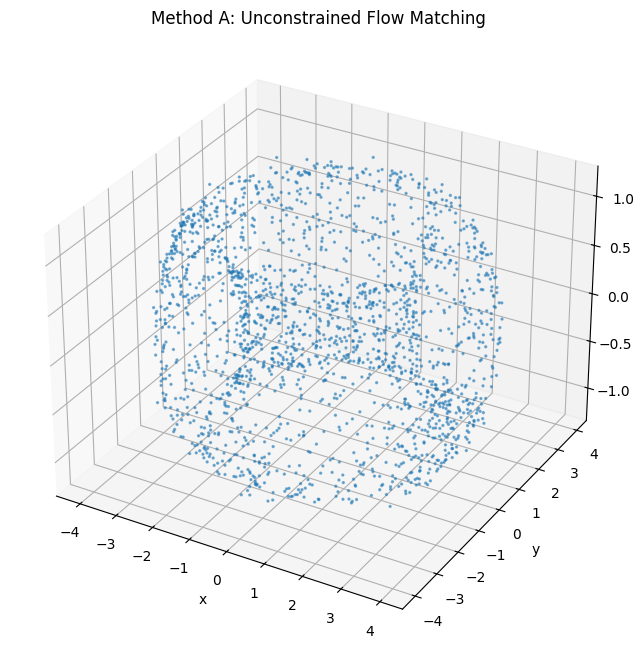

In [18]:
fig = plt.figure(figsize=(8, 8))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    generated_A[:, 0],
    generated_A[:, 1],
    generated_A[:, 2],
    s=2,
    alpha=0.5)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

ax.set_title("Method A: Unconstrained Flow Matching")

plt.show()

# Method B: Soft Constraint

In [19]:
def torus_constraint(x, R=3.0, r=1.0):
    x_coord = x[:, 0]
    y_coord = x[:, 1]
    z_coord = x[:, 2]

    rho = torch.sqrt(x_coord**2 + y_coord**2)
    h = ((rho - R)**2 + z_coord**2 - r**2)

    return h

**Define the gradient h**

The 1e-8 prevents division by zero if a point happens to be extremely close to the z axis.

In [20]:
def torus_constraint_gradient(x, R=3.0):
    x_coord = x[:, 0]
    y_coord = x[:, 1]
    z_coord = x[:, 2]

    rho = torch.sqrt(x_coord**2 + y_coord**2 + 1e-8)

    grad_x = 2 * (rho - R) * x_coord / rho
    grad_y = 2 * (rho - R) * y_coord / rho
    grad_z = 2 * z_coord

    gradient = torch.stack([grad_x, grad_y, grad_z],dim=1)

    return gradient

**Generate Method B**

In [21]:
def generate_method_B(
    model,
    n_samples=2000,
    num_steps=100,
    R=3.0,
    r=1.0,
    lam=0.3,
    epsilon=1e-8):

    # Start from Gaussian noise
    x = torch.randn(n_samples, 3)
    dt = 1.0 / num_steps
    model.eval()
    with torch.no_grad():
        for k in range(num_steps):
            # Current time
            t = torch.full((n_samples, 1), k / num_steps)

            # 1. Normal Flow Matching step
            velocity = model(x, t)
            x_tilde = x + dt * velocity

            # 2. Soft constraint correction
            h = torus_constraint(x_tilde, R, r)
            grad_h = torus_constraint_gradient(x_tilde, R)

            # ||grad h||^2
            grad_norm_squared = (grad_h ** 2).sum(dim=1, keepdim=True)

            # Soft correction
            correction = (lam * h.unsqueeze(1) * grad_h / (grad_norm_squared + epsilon))
            x = x_tilde - correction
    return x

In [22]:
generated_B = generate_method_B(model, n_samples=2000, num_steps=100, R=R,r=r)

print(generated_B.shape)

torch.Size([2000, 3])


Plot Method B

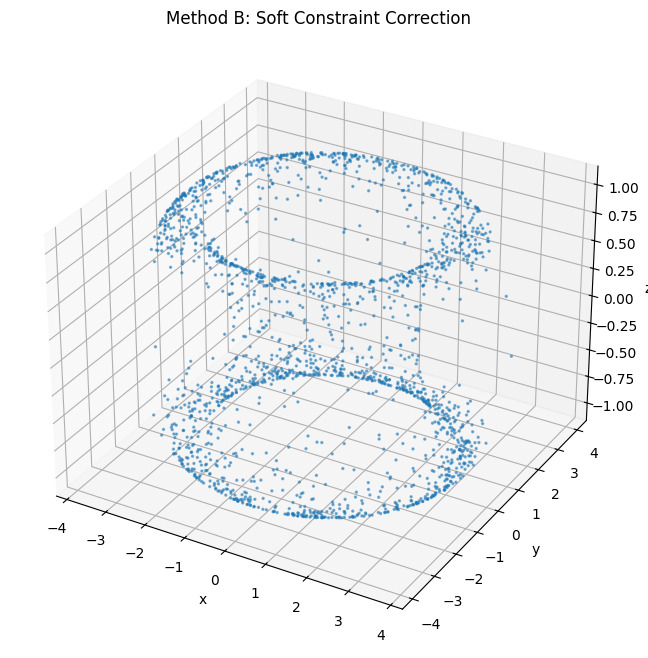

In [23]:
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    generated_B[:, 0],
    generated_B[:, 1],
    generated_B[:, 2],
    s=2,
    alpha=0.5)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

ax.set_title("Method B: Soft Constraint Correction")

plt.show()

Measure feasibility: check how well it satisfies the constraint.

Smaller Eh means points are closer to the torus constraint.

In [24]:
h_B = torus_constraint(generated_B, R, r)

E_h_B = torch.mean(torch.abs(h_B))

print("Method B: E_h =", E_h_B.item())

Method B: E_h = 0.03848955035209656


# Method C: Hard projection every step

In [25]:
def project_to_torus(x, R=3.0, r=1.0):
    x_coord = x[:, 0]
    y_coord = x[:, 1]

    # Angle around the main ring
    theta = torch.atan2(y_coord, x_coord)

    # Center of the local tube
    center = torch.stack(
        [
            R * torch.cos(theta),
            R * torch.sin(theta),
            torch.zeros_like(theta)
        ],
        dim=1
    )

    # Vector from tube center to point
    d = x - center

    # Length of d
    d_norm = torch.norm(d, dim=1, keepdim=True)

    # Project onto tube surface
    projected = (center+ r * d / (d_norm + 1e-8))

    return projected

In [26]:
#Test the projection taking Methid A samples
test_projection = project_to_torus(generated_A, R, r)

In [27]:
#Check the constraint
h_projection = torus_constraint(test_projection, R, r)

print(
    "Mean |h|:",torch.mean(torch.abs(h_projection)).item())

Mean |h|: 1.5711783873939567e-07


B: move me closer to the torus
C: Put me on the torus

In [28]:
def generate_method_C(
    model,
    n_samples=2000,
    num_steps=100,
    R=3.0,
    r=1.0):

    # Start from Gaussian noise
    x = torch.randn(n_samples, 3)
    dt = 1.0 / num_steps
    model.eval()
    with torch.no_grad():
        for k in range(num_steps):
            # Current time
            t = torch.full((n_samples, 1), k / num_steps)

            # 1. Flow Matching step
            velocity = model(x, t)
            x_tilde = x + dt * velocity

            # 2. Hard projection
            x = project_to_torus(x_tilde, R, r)
    return x

In [29]:
generated_C = generate_method_C(model, n_samples=2000, num_steps=100, R=R, r=r)

print(generated_C.shape)

torch.Size([2000, 3])


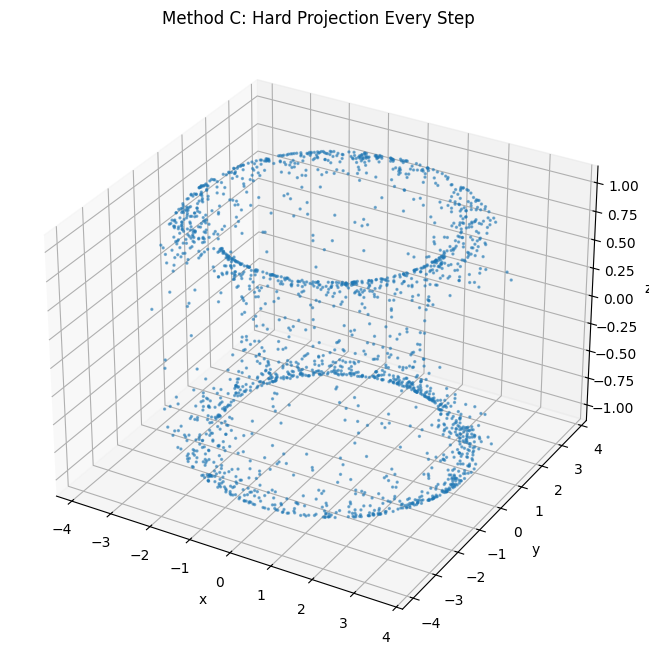

In [30]:
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    generated_C[:, 0],
    generated_C[:, 1],
    generated_C[:, 2],
    s=2,
    alpha=0.5)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

ax.set_title("Method C: Hard Projection Every Step")

plt.show()

# Method D: Terminal

In [31]:
generated_D = project_to_torus(generated_A, R, r)

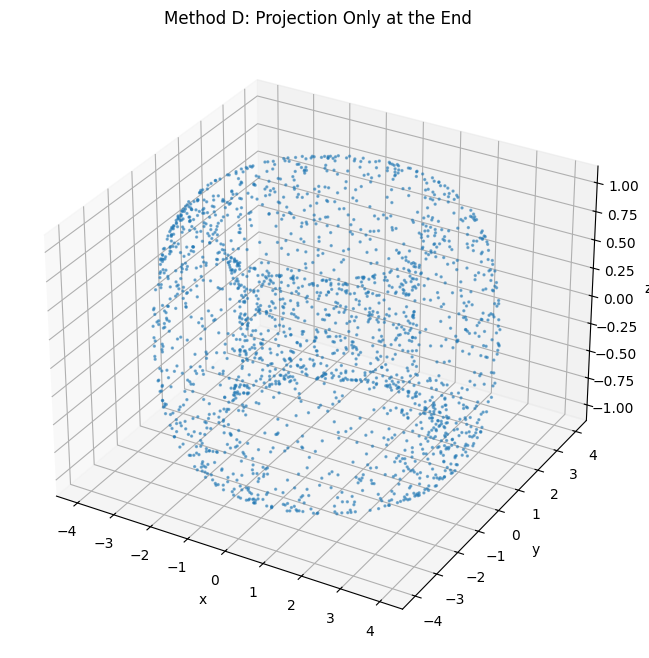

In [32]:
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    generated_D[:, 0],
    generated_D[:, 1],
    generated_D[:, 2],
    s=2,
    alpha=0.5)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

ax.set_title("Method D: Projection Only at the End")

plt.show()

# Comparison Plots final Torus using 4 Methods

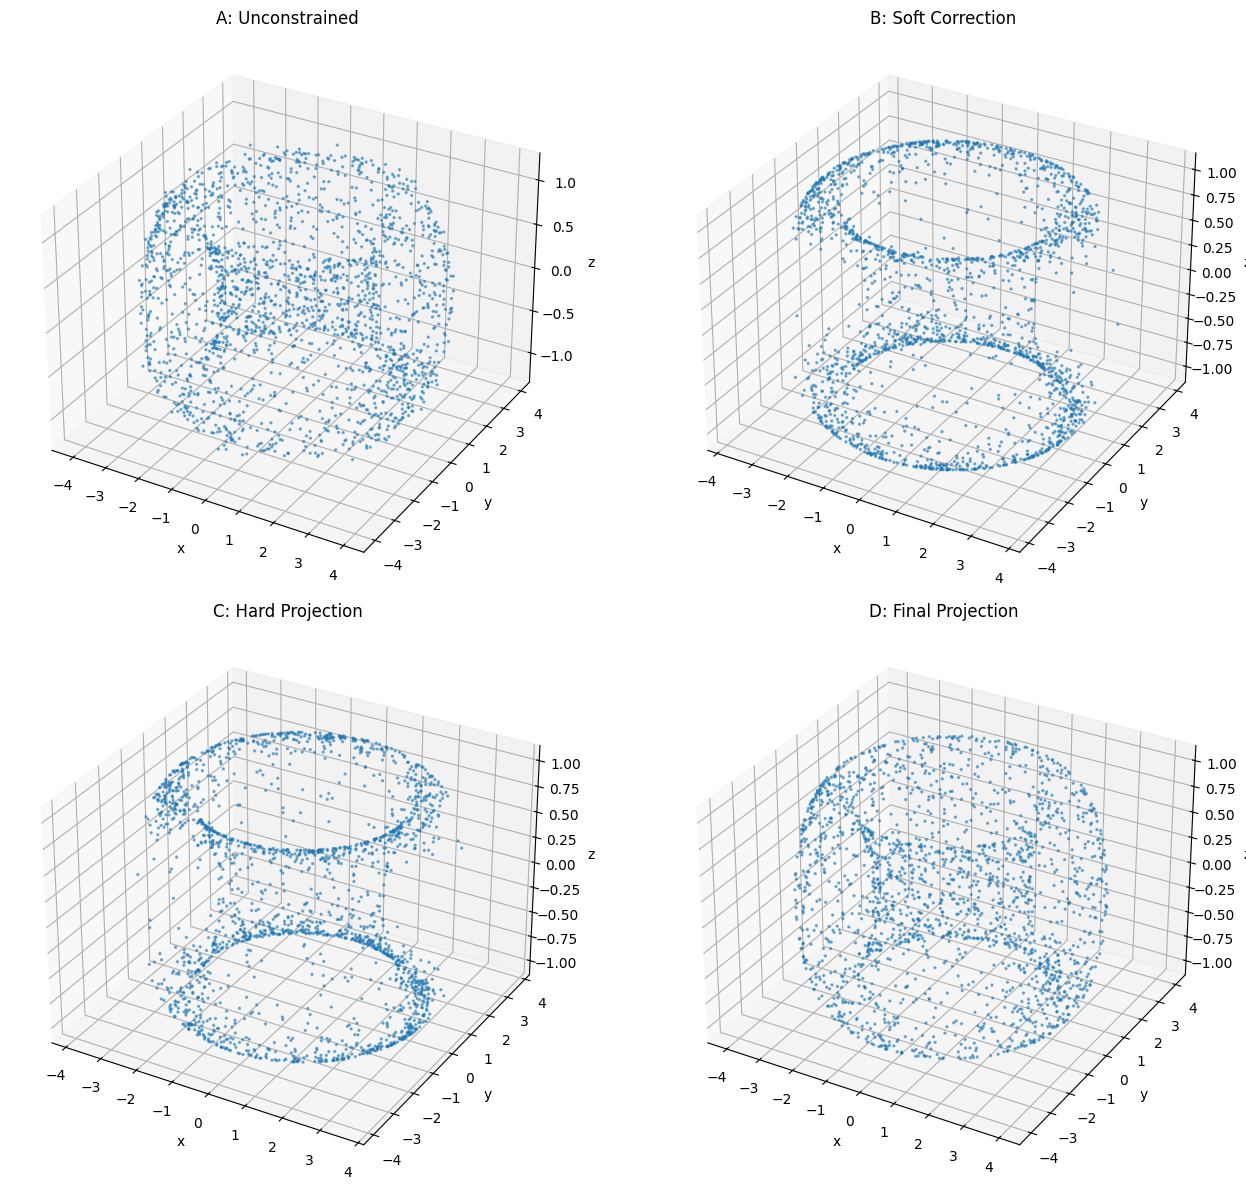

In [33]:
fig = plt.figure(figsize=(14, 12))

methods = [
    ("A: Unconstrained", generated_A),
    ("B: Soft Correction", generated_B),
    ("C: Hard Projection", generated_C),
    ("D: Final Projection", generated_D)]

for i, (title, samples) in enumerate(methods):
    ax = fig.add_subplot(
        2, 2, i + 1,
        projection="3d")

    ax.scatter(
        samples[:, 0],
        samples[:, 1],
        samples[:, 2],
        s=2,
        alpha=0.5)

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")
    ax.set_title(title)

plt.tight_layout()
plt.show()

# Test and Compare A, B, C and D
Use the same trained neural network for all methods.

investigate the trade-off between geometric feasibility and preserving the learned distribution.

- E_h -> how well do they satisfy the torus?
- \phi distribution -> did the methods preserve the non-uniform surface-area distribution?
- Sliced Wasserstein distance -> how close is each generated distribution to the target?
- Eventually, repeat over 10 random seeds

In [34]:
#1. E_h: geometric feasibility
def compute_E_h(samples, R=3.0, r=1.0):
    h = torus_constraint(samples, R, r)
    return torch.mean(torch.abs(h)).item()


E_h_A = compute_E_h(generated_A, R, r)
E_h_B = compute_E_h(generated_B, R, r)
E_h_C = compute_E_h(generated_C, R, r)
E_h_D = compute_E_h(generated_D, R, r)

print("Geometric feasibility (lower is better):")
print(f"A: Unconstrained       E_h = {E_h_A:.6f}")
print(f"B: Soft Correction     E_h = {E_h_B:.6f}")
print(f"C: Hard Projection     E_h = {E_h_C:.6f}")
print(f"D: Final Projection    E_h = {E_h_D:.6f}")

Geometric feasibility (lower is better):
A: Unconstrained       E_h = 0.094229
B: Soft Correction     E_h = 0.038490
C: Hard Projection     E_h = 0.000000
D: Final Projection    E_h = 0.000000


# Plotting their phi distribution against the target

In [35]:
#Phi distribution. The target distribution should have more points around phi = 0 than phi = pi
def compute_phi(samples, R=3.0):
    x = samples[:, 0]
    y = samples[:, 1]
    z = samples[:, 2]

    rho = torch.sqrt(x**2 + y**2)
    phi = torch.atan2(z, rho - R)
    return phi

phi_target = compute_phi(torus_data, R)
phi_A = compute_phi(generated_A, R)
phi_B = compute_phi(generated_B, R)
phi_C = compute_phi(generated_C, R)
phi_D = compute_phi(generated_D, R)

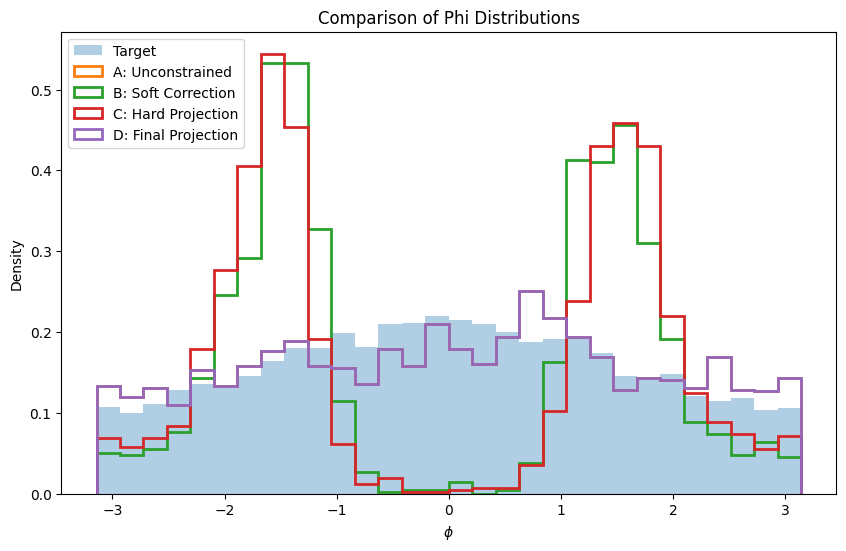

In [36]:
#Comparing phi distribution
bins = np.linspace(-np.pi, np.pi, 31)
plt.figure(figsize=(10, 6))

plt.hist(
    phi_target.numpy(),
    bins=bins,
    density=True,
    alpha=0.35,
    label="Target")

plt.hist(
    phi_A.numpy(),
    bins=bins,
    density=True,
    histtype="step",
    linewidth=2,
    label="A: Unconstrained")

plt.hist(
    phi_B.numpy(),
    bins=bins,
    density=True,
    histtype="step",
    linewidth=2,
    label="B: Soft Correction")

plt.hist(
    phi_C.numpy(),
    bins=bins,
    density=True,
    histtype="step",
    linewidth=2,
    label="C: Hard Projection")

plt.hist(
    phi_D.numpy(),
    bins=bins,
    density=True,
    histtype="step",
    linewidth=2,
    label="D: Final Projection")

plt.xlabel(r"$\phi$")
plt.ylabel("Density")
plt.title("Comparison of Phi Distributions")
plt.legend()
plt.show()

A method can put every point on the torus, good feasibility but
It might have changed where on the torus the points are concetrated.


If a constraint method makes the phi histogram flatter, then it has lost some of the learned distribution, even though geometrically it is perfect.

**Quatify the phi distribution difference** using
1D Wasserstein distance between the phi distributions. Not asked by the TA but wanted to know why the sliced Wasserstein score changes.

Lower = generated phi distribution is closer to the target phi distribution

In [37]:
#Quantify the phi distribution difference
from scipy.stats import wasserstein_distance

#Wasserstein Distance
def phi_wasserstein_distance(phi_generated, phi_target):
    return wasserstein_distance(
        phi_target.detach().cpu().numpy(),
        phi_generated.detach().cpu().numpy()
    )


phi_dist_A = phi_wasserstein_distance(phi_A, phi_target)
phi_dist_B = phi_wasserstein_distance(phi_B, phi_target)
phi_dist_C = phi_wasserstein_distance(phi_C, phi_target)
phi_dist_D = phi_wasserstein_distance(phi_D, phi_target)

print("\nPhi distribution Wasserstein distance:")
print(f"A: {phi_dist_A:.6f}")
print(f"B: {phi_dist_B:.6f}")
print(f"C: {phi_dist_C:.6f}")
print(f"D: {phi_dist_D:.6f}")



Phi distribution Wasserstein distance:
A: 0.115713
B: 0.423715
C: 0.454259
D: 0.115713


# Sliced Wasserstein distance

In [38]:
def sliced_wasserstein_distance(
    generated,
    target,
    n_projections=100):

    generated_np = generated.detach().cpu().numpy()
    target_np = target.detach().cpu().numpy()
    distances = []

    for i in range(n_projections):
        # Random direction
        direction = np.random.randn(3)

        # Normalize to unit vector
        direction = direction / np.linalg.norm(direction)

        # Project both distributions onto direction
        generated_projection = generated_np @ direction
        target_projection = target_np @ direction

        # 1D Wasserstein distance
        distance = wasserstein_distance(
            target_projection,
            generated_projection)

        distances.append(distance)

    return np.mean(distances)

In [39]:
#Evaluate all 4
SW_A = sliced_wasserstein_distance(
    generated_A,
    torus_data,
    n_projections=100
)

SW_B = sliced_wasserstein_distance(
    generated_B,
    torus_data,
    n_projections=100
)

SW_C = sliced_wasserstein_distance(
    generated_C,
    torus_data,
    n_projections=100
)

SW_D = sliced_wasserstein_distance(
    generated_D,
    torus_data,
    n_projections=100
)

print("\nSliced Wasserstein Distance:")
print(f"A: Unconstrained       SW = {SW_A:.6f}")
print(f"B: Soft Correction     SW = {SW_B:.6f}")
print(f"C: Hard Projection     SW = {SW_C:.6f}")
print(f"D: Final Projection    SW = {SW_D:.6f}")


Sliced Wasserstein Distance:
A: Unconstrained       SW = 0.071365
B: Soft Correction     SW = 0.107761
C: Hard Projection     SW = 0.145508
D: Final Projection    SW = 0.077335


# Summary Test and Comparison

In [40]:
results = {
    "Method": [
        "A: Unconstrained",
        "B: Soft Correction",
        "C: Hard Projection",
        "D: Final Projection"
    ],

    "E_h": [
        E_h_A,
        E_h_B,
        E_h_C,
        E_h_D
    ],

    "Phi Wasserstein": [
        phi_dist_A,
        phi_dist_B,
        phi_dist_C,
        phi_dist_D
    ],
}

import pandas as pd
results_df = pd.DataFrame(results)
print(results_df)

                Method           E_h  Phi Wasserstein
0     A: Unconstrained  9.422910e-02         0.115713
1   B: Soft Correction  3.848955e-02         0.423715
2   C: Hard Projection  1.017749e-07         0.454259
3  D: Final Projection  1.571178e-07         0.115713


Repeat experiment over 10 random seeds

In [41]:
# Repeat experiment over 10 random seeds
# Same trained model for A, B, C and D

num_seeds = 10
n_samples = 2000

all_results = []

for seed in range(num_seeds):

    print(f"\nRunning seed {seed + 1}/{num_seeds}")

    # Set random seeds
    np.random.seed(seed)
    torch.manual_seed(seed)

    # Generate 2000 samples for each method
    generated_A = generate_samples(
        model,
        n_samples=n_samples,
        num_steps=100
    )

    generated_B = generate_method_B(
        model,
        n_samples=n_samples,
        num_steps=100,
        R=R,
        r=r
    )

    generated_C = generate_method_C(
        model,
        n_samples=n_samples,
        num_steps=100,
        R=R,
        r=r
    )

    generated_D = project_to_torus(
        generated_A,
        R,
        r
    )

    # Calculate E_h
    E_h_A = compute_E_h(generated_A, R, r)
    E_h_B = compute_E_h(generated_B, R, r)
    E_h_C = compute_E_h(generated_C, R, r)
    E_h_D = compute_E_h(generated_D, R, r)

    # Calculate Sliced Wasserstein
    SW_A = sliced_wasserstein_distance(
        generated_A,
        torus_data,
        n_projections=100
    )

    SW_B = sliced_wasserstein_distance(
        generated_B,
        torus_data,
        n_projections=100
    )

    SW_C = sliced_wasserstein_distance(
        generated_C,
        torus_data,
        n_projections=100
    )

    SW_D = sliced_wasserstein_distance(
        generated_D,
        torus_data,
        n_projections=100
    )

    # Save results
    all_results.append({
        "Seed": seed,
        "Method": "A: Unconstrained",
        "E_h": E_h_A,
        "Sliced Wasserstein": SW_A
    })

    all_results.append({
        "Seed": seed,
        "Method": "B: Soft Correction",
        "E_h": E_h_B,
        "Sliced Wasserstein": SW_B
    })

    all_results.append({
        "Seed": seed,
        "Method": "C: Hard Projection",
        "E_h": E_h_C,
        "Sliced Wasserstein": SW_C
    })

    all_results.append({
        "Seed": seed,
        "Method": "D: Final Projection",
        "E_h": E_h_D,
        "Sliced Wasserstein": SW_D
    })

    print("Done.")


Running seed 1/10
Done.

Running seed 2/10
Done.

Running seed 3/10
Done.

Running seed 4/10
Done.

Running seed 5/10
Done.

Running seed 6/10
Done.

Running seed 7/10
Done.

Running seed 8/10
Done.

Running seed 9/10
Done.

Running seed 10/10
Done.


In [42]:
import pandas as pd

results_10_seeds = pd.DataFrame(all_results)

print(results_10_seeds)

    Seed               Method           E_h  Sliced Wasserstein
0      0     A: Unconstrained  9.810274e-02            0.096223
1      0   B: Soft Correction  3.811309e-02            0.127766
2      0   C: Hard Projection  1.013875e-07            0.153815
3      0  D: Final Projection  1.518130e-07            0.095695
4      1     A: Unconstrained  9.401343e-02            0.106174
5      1   B: Soft Correction  3.821356e-02            0.131919
6      1   C: Hard Projection  1.006722e-07            0.155585
7      1  D: Final Projection  1.492798e-07            0.099123
8      2     A: Unconstrained  9.365587e-02            0.075694
9      2   B: Soft Correction  3.725073e-02            0.119280
10     2   C: Hard Projection  1.054704e-07            0.139447
11     2  D: Final Projection  1.497567e-07            0.076418
12     3     A: Unconstrained  9.448798e-02            0.081201
13     3   B: Soft Correction  3.767569e-02            0.112982
14     3   C: Hard Projection  1.030266e

Mean and Standard Deviation

In [43]:
summary = (
    results_10_seeds
    .groupby("Method")
    [["E_h", "Sliced Wasserstein"]]
    .agg(["mean", "std"])
)

print(summary)

                              E_h               Sliced Wasserstein          
                             mean           std               mean       std
Method                                                                      
A: Unconstrained     9.434726e-02  2.021875e-03           0.086813  0.011812
B: Soft Correction   3.771985e-02  3.748276e-04           0.125493  0.011104
C: Hard Projection   1.016408e-07  2.243800e-09           0.145957  0.009069
D: Final Projection  1.507848e-07  2.166649e-09           0.083474  0.013952
